In [ ]:
!pip install qiskit qiskit-aer matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 32.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 38.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 29.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-aer]


In [ ]:
# 5. Implementing a 5 qubit Quantum Fourier Transform

=== 1. Puzzle State Simulation Demo ===
Most probable measured state: 000010011011101100
Simulation completed successfully!

=== 2. Quantum Coin Flip Demonstration ===
Coin Flip Results:
Tails (1): 490 (49.00%)
Heads (0): 510 (51.00%)


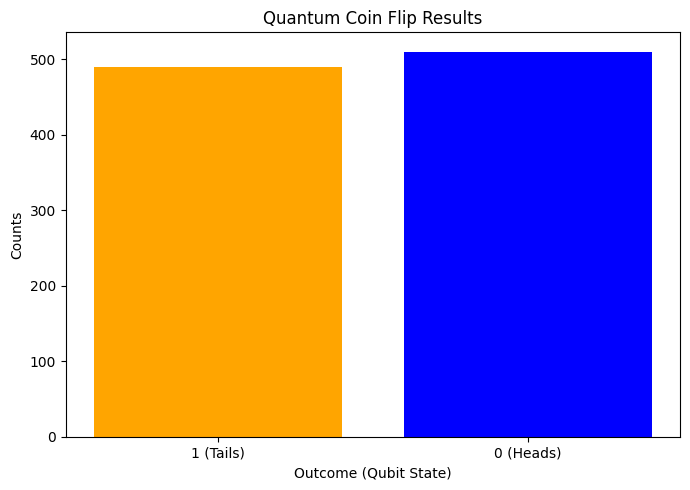

In [ ]:
# Practical 5: Tarrataca's Quantum Production System
# 3-Puzzle State Simulation and Quantum Coin Flip

# Step 1: Import required libraries
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
import matplotlib.pyplot as plt


# ==========================================
# PART 1: PUZZLE STATE SIMULATION DEMO
# ==========================================

def run_puzzle_state_demo():

    print("=== 1. Puzzle State Simulation Demo ===")

    # Step 2: Define initial and goal states
    initial_state = [2, 5, 3, 1, 8, 6, 4, 7, None]

    goal_state = [1, 2, 3, 4, 5, 6, 7, 8, None]

    # Step 3: Create an 18-qubit quantum circuit
    # First 9 qubits represent initial state
    # Next 9 qubits represent goal state / swaps

    qc = QuantumCircuit(18, 18)

    # Step 4: Initialize circuit based on non-empty tiles
    for i, tile in enumerate(initial_state):

        if tile is not None:
            qc.x(i)

    # Step 5: Apply swaps mapping initial layout
    # to the target layout

    for i, tile in enumerate(goal_state):

        if tile is not None:

            if tile in initial_state:

                initial_index = initial_state.index(tile)

                target_index = goal_state.index(tile)

                qc.swap(i, initial_index + 9)

                qc.swap(i, target_index + 9)

    # Step 6: Measure all 18 qubits
    qc.measure(range(18), range(18))

    # Step 7: Initialize quantum simulator
    backend = Aer.get_backend('qasm_simulator')

    # Step 8: Transpile the circuit
    compiled_qc = transpile(qc, backend)

    # Step 9: Execute the circuit
    job = backend.run(compiled_qc, shots=1024)

    result = job.result()

    # Step 10: Get measurement counts
    counts = result.get_counts()

    # Step 11: Find the most probable measured state
    max_state = max(counts, key=counts.get)

    print("Most probable measured state:", max_state)

    print("Simulation completed successfully!\n")


# ==========================================
# PART 2: QUANTUM COIN FLIP DEMONSTRATION
# ==========================================

def run_quantum_coin_flip():

    print("=== 2. Quantum Coin Flip Demonstration ===")

    # Step 1: Define a one-qubit quantum circuit
    qc = QuantumCircuit(1, 1)

    # Step 2: Apply Hadamard gate
    qc.h(0)

    # Step 3: Measure the qubit
    qc.measure(0, 0)

    # Step 4: Initialize quantum simulator
    backend = Aer.get_backend('qasm_simulator')

    # Step 5: Transpile the circuit
    compiled_qc = transpile(qc, backend)

    # Step 6: Set number of shots
    num_shots = 1000

    # Step 7: Execute the circuit
    job = backend.run(compiled_qc, shots=num_shots)

    result = job.result()

    # Step 8: Get measurement results
    counts = result.get_counts()

    # Step 9: Display coin flip results
    print("Coin Flip Results:")

    for outcome, count in counts.items():

        state_label = "Heads (0)" if outcome == '0' else "Tails (1)"

        print(
            f"{state_label}: {count} "
            f"({count / num_shots * 100:.2f}%)"
        )

    # Step 10: Plot the results
    outcomes = list(counts.keys())

    counts_list = list(counts.values())

    plt.figure(figsize=(7, 5))

    plt.bar(
        outcomes,
        counts_list,
        color=['blue' if x == '0' else 'orange' for x in outcomes]
    )

    plt.xlabel('Outcome (Qubit State)')

    plt.ylabel('Counts')

    plt.title('Quantum Coin Flip Results')

    plt.xticks(outcomes, ['0 (Heads)' if x == '0'
                          else '1 (Tails)' for x in outcomes])

    plt.tight_layout()

    plt.show()


# ==========================================
# MAIN PROGRAM
# ==========================================

if __name__ == "__main__":

    run_puzzle_state_demo()

    run_quantum_coin_flip()
